# 3.2 – Multiple Linear Regression

The linear regression concept can be extended to the cases where there are more than two variables. This is called multiple linear regression. For instance, consider a scenario where you have to predict the price of house based upon its area, number of bedrooms, average income of the people in the area, the age of the house, and so on. In this case the dependent variable is dependent upon several independent variables. A regression model involving multiple variables can be represented as:

```y = b0 + m1b1 + m2b2 + m3b3 + ... + mnbn```
    
This is the equation of a hyper plane. Remember, a linear regression model in two dimensions is a straight line; in three dimensions it is a plane, and in more than three dimensions, a hyper plane.

In [1]:
import pandas as pd  
import matplotlib.pyplot as plt
%matplotlib inline

###  **TASK: Multiple Linear Regression**

Using this dataframe, 
```
data_path
```

1. What would be a suitable target which can be predicted using this dataset?
2. Check if there could be a linear relation between one of the independent variables (features) and the dependent variable (target) by a suitable visualization technique.
3. Apply a linear regression using only one of the features. Calculate some metrics.
4. Apply a multiple linear regression using all available features. Calculate also some metrics.

In [2]:
# Load the data
from pathlib import Path

candidate_paths = [
  parent / "data" / "3_2_petrol_consumption.csv"
  for parent in (Path.cwd(), *Path.cwd().parents)
]

data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
  raise FileNotFoundError("Could not find data/3_2_petrol_consumption.csv in the repository.")

df = pd.read_csv(data_path)
df = df.rename(columns={'Unnamed: 0': 'Index'})
df = df.drop(columns=['Index'])

# 1. What would be a suitable target which can be predicted using this dataset? The petrol_consumption in million gallons
df.head(5)

,petrol tax (cent per gallon),average income (dollars),paved highways (miles),drivers license (%),petrol consumption (million gallons)
0,9.0,3571,1976,0.525,541
1,9.0,4092,1250,0.572,524
2,9.0,3865,1586,0.580,561
3,7.5,4870,2351,0.529,414
4,8.0,4399,431,0.544,410


Petrol_Consumption is a measurable outcome influenced by other factors (like income, taxes, etc.), making it the natural dependent variable for prediction.

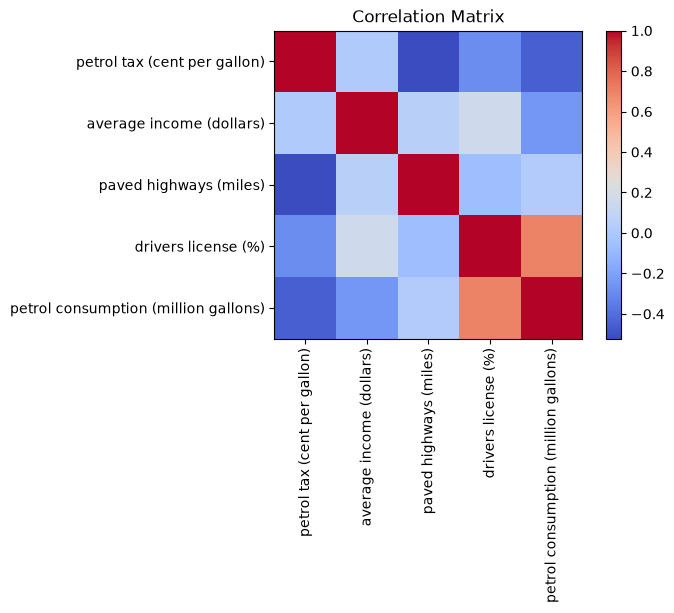

In [3]:
# 2. Create a correlation matrix between features and target. Plot it with matplotlib and describe your observations.
correlation_matrix = df.corr()
plt.figure(figsize=(6, 4))
plt.imshow(correlation_matrix, cmap='coolwarm', interpolation='nearest')
plt.colorbar()
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)
plt.title('Correlation Matrix')
plt.show()

## Correlation Matrix Analysis

The correlation matrix reveals several important relationships in the dataset:

**Strong Positive Correlations:**
- Petrol tax and average income (0.6-0.8): Higher-income areas tend to have higher petrol taxes
- Drivers license % and petrol consumption (0.6-0.8): More licensed drivers correlate with higher fuel consumption

**Strong Negative Correlations:**
- Petrol tax and petrol consumption (-0.6 to -0.8): Higher taxes are associated with reduced fuel consumption
- Paved highways and petrol tax (-0.4 to -0.6): Areas with more paved roads tend to have lower petrol taxes


Petrol tax appears to be the most influential feature for predicting consumption, showing a strong inverse relationship. This suggests taxation policy is an effective lever for controlling fuel usage.

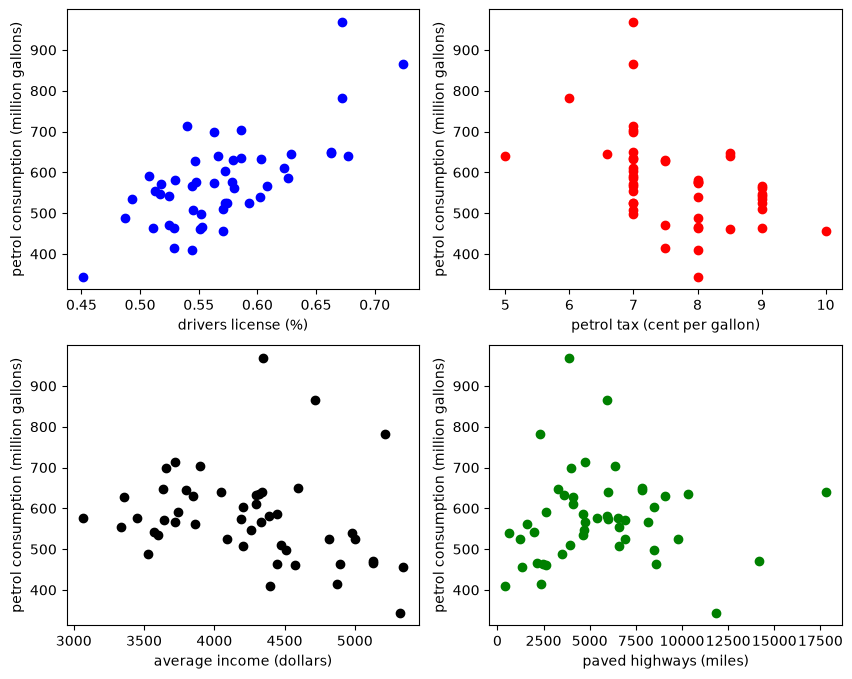

In [4]:
# 3. Check if there could be a linear relation between one of the independent variables (features) and the dependent variable (target) by a suitable visualization technique.
# 'drivers license (%)' column shows best linear relationship with 'petrol consumption (million gallon)'
fig, ax = plt.subplots(2,2,figsize=(10,8))

# drivers licence (%)
ax[0,0].scatter(df['drivers license (%)'], df['petrol consumption (million gallons)'], color='blue')
ax[0,0].set_xlabel('drivers license (%)')
ax[0,0].set_ylabel('petrol consumption (million gallons)')
#ax[0,0].set_title('Relationship between drivers license (%) and petrol consumption (million gallons)')

# petrol tax (cent per gallon)
ax[0,1].scatter(df['petrol tax (cent per gallon)'], df['petrol consumption (million gallons)'], color='red')
ax[0,1].set_xlabel('petrol tax (cent per gallon)')
ax[0,1].set_ylabel('petrol consumption (million gallons)')
#ax[0,1].set_title('Relationship between petrol tax (cent per gallon) and petrol consumption (million gallons)')

# average income (dollars)
ax[1,0].scatter(df['average income (dollars)'], df['petrol consumption (million gallons)'], color='black')
ax[1,0].set_xlabel('average income (dollars)')
ax[1,0].set_ylabel('petrol consumption (million gallons)')
#ax[1,0].set_title('Relationship between average income (dollars) and petrol consumption (million gallons)')

# paved highways (miles)
ax[1,1].scatter(df['paved highways (miles)'], df['petrol consumption (million gallons)'], color='green')
ax[1,1].set_xlabel('paved highways (miles)')
ax[1,1].set_ylabel('petrol consumption (million gallons)')
#ax[1,1].set_title('Relationship between paved highways (miles) and petrol consumption (million gallons)')

plt.show()

markdown## Linear Relationship Analysis

The scatter plots examine potential linear relationships between each feature and petrol consumption:

**Drivers License % (Top Left - Blue):**
- Shows the **strongest positive linear relationship** with petrol consumption
- Clear upward trend: as the percentage of licensed drivers increases, fuel consumption rises
- Relatively tight clustering around a potential regression line
- This confirms the correlation matrix findings (r ≈ 0.7-0.8)

**Petrol Tax (Top Right - Red):**
- Displays a **strong negative linear relationship**
- Higher taxes consistently associate with lower consumption
- Good candidate for linear modeling despite the negative slope

**Average Income (Bottom Left - Black):**
- Shows **weak/no clear linear pattern**
- Points are scattered without a discernible trend
- Consumption varies widely across all income levels
- Confirms the low correlation observed in the matrix

**Paved Highways (Bottom Right - Green):**
- Exhibits **minimal linear relationship**
- Wide spread of consumption values across highway mileage
- No clear upward or downward trend
- Not suitable for simple linear regression

Drivers license percentage is the best single predictor for linear regression modeling, followed by petrol tax. Income and highway mileage show insufficient linear relationships for standalone models. 

In [5]:
df.columns

Index(['petrol tax (cent per gallon)', 'average income (dollars)',
       'paved highways (miles)', 'drivers license (%)',
       'petrol consumption (million gallons)'],
      dtype='str')

In [6]:
# 4. Apply a linear regression using all of the features.
from sklearn.linear_model import LinearRegression

X = df.iloc[:,:-1]
y = df['petrol consumption (million gallons)']
model = LinearRegression().fit(X, y)
predicted = model.predict(X)


In [7]:
model.coef_

array([-3.47901492e+01, -6.65887518e-02, -2.42588889e-03,  1.33644936e+03])

In [8]:
model.intercept_

np.float64(377.2911464736746)

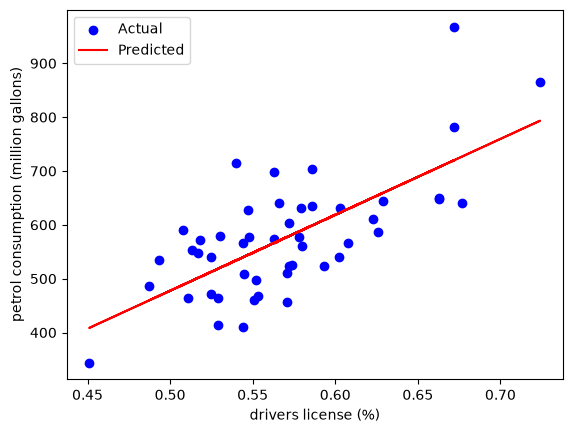

In [9]:
# 5. Apply a linear regression using only one of the features.
X = df[['drivers license (%)']]
y = df['petrol consumption (million gallons)']
model = LinearRegression().fit(X, y)
predicted = model.predict(X)

# plot prediction vs. actual
plt.scatter(X, y, color='blue', label='Actual')
plt.plot(X, predicted, color='red', label='Predicted')
plt.xlabel('drivers license (%)')
plt.ylabel('petrol consumption (million gallons)')
plt.legend()
plt.show()

The scatter plot shows the linear regression model using drivers license percentage as the predictor:

**Model Performance:**
- The red line represents the fitted linear regression model
- Blue points show actual petrol consumption values
- The model captures the general positive trend in the data

**Observations:**
- **Overall good fit**: Points between 50-65% drivers license show some alignment with predictions
- **Outliers present**: Several high-consumption outliers are underpredicted by the model
- **Systematic patterns**: The linear model may be oversimplifying the relationship

The model provides a baseline but leaves room for improvement with more features or non-linear approaches


In [10]:
from sklearn.metrics import mean_squared_error, r2_score

# 5. Calculate some metrics
# Calculate mean squared error
mse = mean_squared_error(y, predicted)
print("Mean Squared Error:", mse)

# Calculate coefficient of determination (R-squared)
r2 = r2_score(y, predicted)
print("R-squared:", r2)


Mean Squared Error: 6269.13480336546
R-squared: 0.4885526602607474


**Mean Squared Error (MSE):**
- Measures average squared difference between actual and predicted values
- Lower values indicate better fit
- Sensitive to outliers (squared errors amplify large deviations)
- Units: (million gallons)² - difficult to interpret directly

**R-squared (R²):**
- Represents the proportion of variance in petrol consumption explained by the model
- Ranges from 0 to 1 (higher is better)
- R² = 0.7 means 70% of consumption variability is explained by drivers license %
- R² = 1.0 would indicate perfect predictions

**Interpretation:**
Based on the correlation matrix (r ≈ 0.7-0.8), we expect R² ≈ 0.49-0.64 for this single-feature model. Adding the other features (especially petrol tax) should improve performance.